### Checkpoint 1

Implement your algorithm to process and annotate the traces of the 20 unipolar electrogram signals, identifying focal activity based on activation patterns and signal morphology.

The algorithm must return the following outputs:

1. **Activation Annotations**: for each of the 20 signals, generate a list of activation times. These activation times correspond to the local minima of the first derivative of the signal, indicating the moments of depolarization at each electrode.
2. **Focal proximity**: assign a score of 1 to the sensor closest to the focal activity and 0 to all others. If the focal activity is within two sensors (up to a specified tolerance), assign 0.5 to each of the two sensors.
This output should be guided by signal morphology: focal activity is expected to correspond to a QS morphology (i.e., a single dominant negative deflection).

Provide your algorithm's implementation in this notebook to annotate the traces of the 20 unipolar signals and identify focal activity based on activation patterns and waveform morphology.



In [1]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema, savgol_filter

In [2]:
# load data
signals = np.load('checkpoint1dataset.npy')

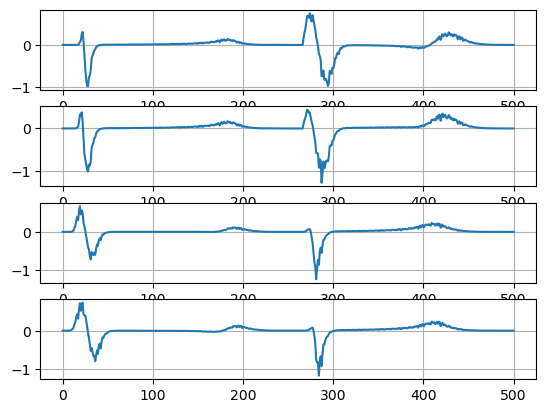

In [3]:
# select event to be display
ind_event = 2

# select a spline (options: 0,1,2,3,4)
ind_spline = 2

# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

signals_event = signals[ind_event,:,:]

In [4]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.signal import savgol_filter, argrelextrema

# # --- CONFIGURAZIONE ---
# ev_test = 3
# spline_sensors = [8, 9, 10, 5] 
# window_length = 15
# poly_order = 3
# min_dist = 100 

# # Pre-processing (Savgol è essenziale per l'Onset)
# signals_filtered = np.zeros_like(signals)
# for ev in range(signals.shape[0]):
#     for sens in range(signals.shape[1]):
#         signals_filtered[ev, sens, :] = savgol_filter(signals[ev, sens, :], window_length, poly_order)

# # --- PLOTTING CON ANALISI ONSET ---
# n_sens = len(spline_sensors)
# fig, axs = plt.subplots(2, n_sens, figsize=(4 * n_sens, 9), sharex=True)

# if n_sens == 1: axs = axs.reshape(2, 1)

# for i, sens_idx in enumerate(spline_sensors):
#     sig_filt = signals_filtered[ev_test, sens_idx, :]
#     ds_filt = np.diff(sig_filt)
    
#     # 1. Trova i picchi di attivazione (minimi derivata)
#     min_indices = argrelextrema(ds_filt, np.less)[0]
#     selected_peaks = []
#     if len(min_indices) > 0:
#         depths = ds_filt[min_indices]
#         candidates = min_indices[np.argsort(depths)]
#         for c in candidates:
#             if len(selected_peaks) == 0 or all(abs(c - p) > min_dist for p in selected_peaks):
#                 selected_peaks.append(c)
#             if len(selected_peaks) == 2: break
#     selected_peaks.sort()

#     # 2. Calcolo dell'Onset (Distacco dalla baseline)
#     onsets = []
#     for p in selected_peaks:
#         # Analizziamo una finestra di 50 campioni prima del picco
#         search_back = 50
#         start_win = max(0, p - search_back)
#         window = sig_filt[start_win : p]
        
#         # Calcoliamo la baseline e una soglia di distacco dinamica (noise floor)
#         # Usiamo i primi 10 campioni della finestra come riferimento di "quiete"
#         local_baseline = np.mean(sig_filt[start_win : start_win + 10])
#         noise_std = np.std(sig_filt[start_win : start_win + 10])
#         threshold = max(3 * noise_std, 0.02 * (np.max(sig_filt) - np.min(sig_filt)))
        
#         # Torniamo indietro dal picco p finché il segnale non rientra nella soglia
#         onset_idx = p
#         for k in range(p, start_win, -1):
#             if abs(sig_filt[k] - local_baseline) < threshold:
#                 onset_idx = k
#                 break
#         onsets.append(onset_idx)

#     # --- RIGA 1: SEGNALE + ONSET ---
#     axs[0, i].plot(sig_filt, color='blue', linewidth=1.5, label='Filt')
#     for idx_o in onsets:
#         # Cerchio verde sul punto di distacco
#         axs[0, i].plot(idx_o, sig_filt[idx_o], 'go', markersize=10, markeredgecolor='black', label='Onset' if idx_o == onsets[0] else "")
#         # Linea verticale per confronto temporale
#         axs[0, i].axvline(x=idx_o, color='green', linestyle='--', alpha=0.6)
#         # Annotazione del tempo di onset
#         axs[0, i].text(idx_o, sig_filt[idx_o] + 0.1, f'T:{idx_o}', color='green', fontweight='bold', ha='center')

#     axs[0, i].set_title(f'Sensore {sens_idx}', fontsize=12, fontweight='bold')
#     axs[0, i].grid(True, alpha=0.2)
#     if i == 0: axs[0, i].legend()

#     # --- RIGA 2: DERIVATA ---
#     axs[1, i].plot(ds_filt, color='red', linewidth=1)
#     for p in selected_peaks:
#         axs[1, i].plot(p, ds_filt[p], 'ro')
#         axs[1, i].text(p, ds_filt[p] - 0.05, f'Act:{p}', color='red', fontsize=8, ha='center')
    
#     axs[1, i].set_title('Derivata (Pendenza)', fontsize=10)
#     axs[1, i].grid(True, alpha=0.2)

# plt.suptitle(f'Analisi Onset vs Activation - Evento {ev_test}\nIl cerchio verde indica il primo distacco dalla baseline (indipendentemente dalla R o S)', 
#              fontsize=14, fontweight='bold', y=0.98)
# plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# plt.show()

In [11]:
import numpy as np
from scipy.signal import argrelextrema, savgol_filter

def GroupSolutionCP1(signals_event):

    # Filtraggio con Savgol 
    sig_cleaned = savgol_filter(signals_event, window_length=11, polyorder=3, axis=1)

    n_sensors = sig_cleaned.shape[0]
    timings = []

    min_dist = 100
    time_tol = 2

    act_times = [[], []]
    qs_scores = [[], []]
    slopes_list = [[], []]
    onsets_list = [[], []]

    for i in range(n_sensors):

        # Analisi della derivata per trovare i picchi di attivazione
        sig_i = sig_cleaned[i, :]
        ds = np.gradient(sig_i)

        # Trova i minimi locali della derivata (picchi di attivazione)
        min_indices = argrelextrema(ds, np.less)[0]

        selected = []

        qs_status = [0.0, 0.0]
        sensor_slopes = [np.nan, np.nan]
        sensor_onsets = [np.nan, np.nan]

        # Se ci sono picchi di attivazione, analizziamo i primi due più profondi (se presenti)
        if len(min_indices) > 0:

            depths = ds[min_indices]
            candidates = min_indices[np.argsort(depths)]

            for idx in candidates:

                if len(selected) == 0:
                    selected.append(idx)

                # Controlla la distanza minima tra i picchi selezionati
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break

            selected.sort()

            # Analisi dei picchi selezionati per QS Score, Slope e Onset
            for j, val in enumerate(selected):

                # Analizziamo una finestra di 60 campioni intorno al picco per calcolare baseline, max pos/neg e slope
                win_start = max(0, val - 30)
                win_end = min(sig_cleaned.shape[1], val + 30)

                # Calcoliamo la baseline come media dei primi 5 campioni della finestra (o meno se siamo vicini all'inizio)
                baseline = np.mean(sig_i[win_start : min(win_start + 5, len(sig_i))])

                pre_seg = sig_i[win_start:val]
                post_seg = sig_i[val:win_end]

                max_pos = np.max(pre_seg) - baseline if pre_seg.size else 0
                max_neg = np.min(post_seg) - baseline if post_seg.size else 0

                # Calcolo del QS Score (più negativo è il picco, migliore è il punteggio)
                ratio = max_pos / (abs(max_neg) + 1e-6)
                qs_status[j] = max(0, 1 - ratio)

                # SLOPE
                sensor_slopes[j] = ds[val]

                # INIZIO DEL BATTITO
                search_back = 40
                start_w = max(0, val - search_back)

                # Calcoliamo una soglia dinamica basata sulla deviazione standard locale per identificare l'inizio del battito
                local_std = np.std(sig_i[start_w : min(start_w + 5, len(sig_i))])
                thresh = max(3 * local_std, 0.05 * abs(max_neg))

                onset_idx = val

                for k in range(val, start_w, -1):
                    if abs(sig_i[k] - baseline) < thresh:
                        onset_idx = k
                        break

                sensor_onsets[j] = onset_idx

        row_time = [np.nan, np.nan]

        for idx_j, val_time in enumerate(selected):
            row_time[idx_j] = int(val_time)

        timings.append(row_time)

        # Raccogliamo i dati per la valutazione della localizzazione
        for j in range(2):

            t_val = row_time[j] if not np.isnan(row_time[j]) else np.inf

            act_times[j].append(t_val)
            qs_scores[j].append(qs_status[j])
            slopes_list[j].append(sensor_slopes[j])
            onsets_list[j].append(sensor_onsets[j])

    LS_array = np.zeros((n_sensors, 2))

    # Valutazione della localizzazione
    for j in range(2):

        times = np.array(act_times[j])
        qs = np.array(qs_scores[j])
        slopes = np.array(slopes_list[j])
        onsets = np.array(onsets_list[j])

        valid_idxs = np.where(times < np.inf)[0]

        if len(valid_idxs) == 0:
            continue

        # Calcolo dello score combinando tutte le informazioni disponibili (tempi, QS, slope, onset)
        scores = []

        min_time = np.min(times[valid_idxs])
        max_s = np.max(np.abs(slopes[valid_idxs]))


        for idx in valid_idxs:

            early_score = -(times[idx] - min_time)

            onset_score = -(onsets[idx] - np.nanmin(onsets))

            slope_score = abs(slopes[idx])/(max_s + 1e-6)   # slope negativa migliore

            qs_score = qs[idx]

            total = (
                0.45 * early_score +
                0.25 * onset_score +
                0.20 * slope_score +
                0.10 * qs_score
            )

            scores.append((idx, total))

        scores.sort(key=lambda x: x[1], reverse=True)

        best = scores[0][0]

        winners = [best]

        # Controlliamo se il secondo classificato è abbastanza vicino al primo in termini di tempo
        if len(scores) > 1:

            second = scores[1][0]

            if abs(times[second] - times[best]) <= time_tol:
                winners.append(second)

        # Assegnazione punteggi
        if len(winners) == 1:
            LS_array[winners[0], j] = 1.0
        else:
            LS_array[winners[0], j] = 0.5
            LS_array[winners[1], j] = 0.5

    return timings, LS_array.tolist()

In [10]:
# test it

timings_event, LS_event = GroupSolutionCP1(signals_event)

print(timings_event)
print("LS_event", LS_event)

[[21, 311], [20, 308], [23, 297], [26, 294], [54, 356], [42, 346], [7, 305], [7, 296], [24, 283], [23, 280], [26, 277], [26, 280], [111, 371], [101, 359], [70, 324], [60, 312], [111, 375], [101, 362], [70, 327], [60, 315]]
LS_event [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.5, 0.0], [0.5, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.5], [0.0, 0.5], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]


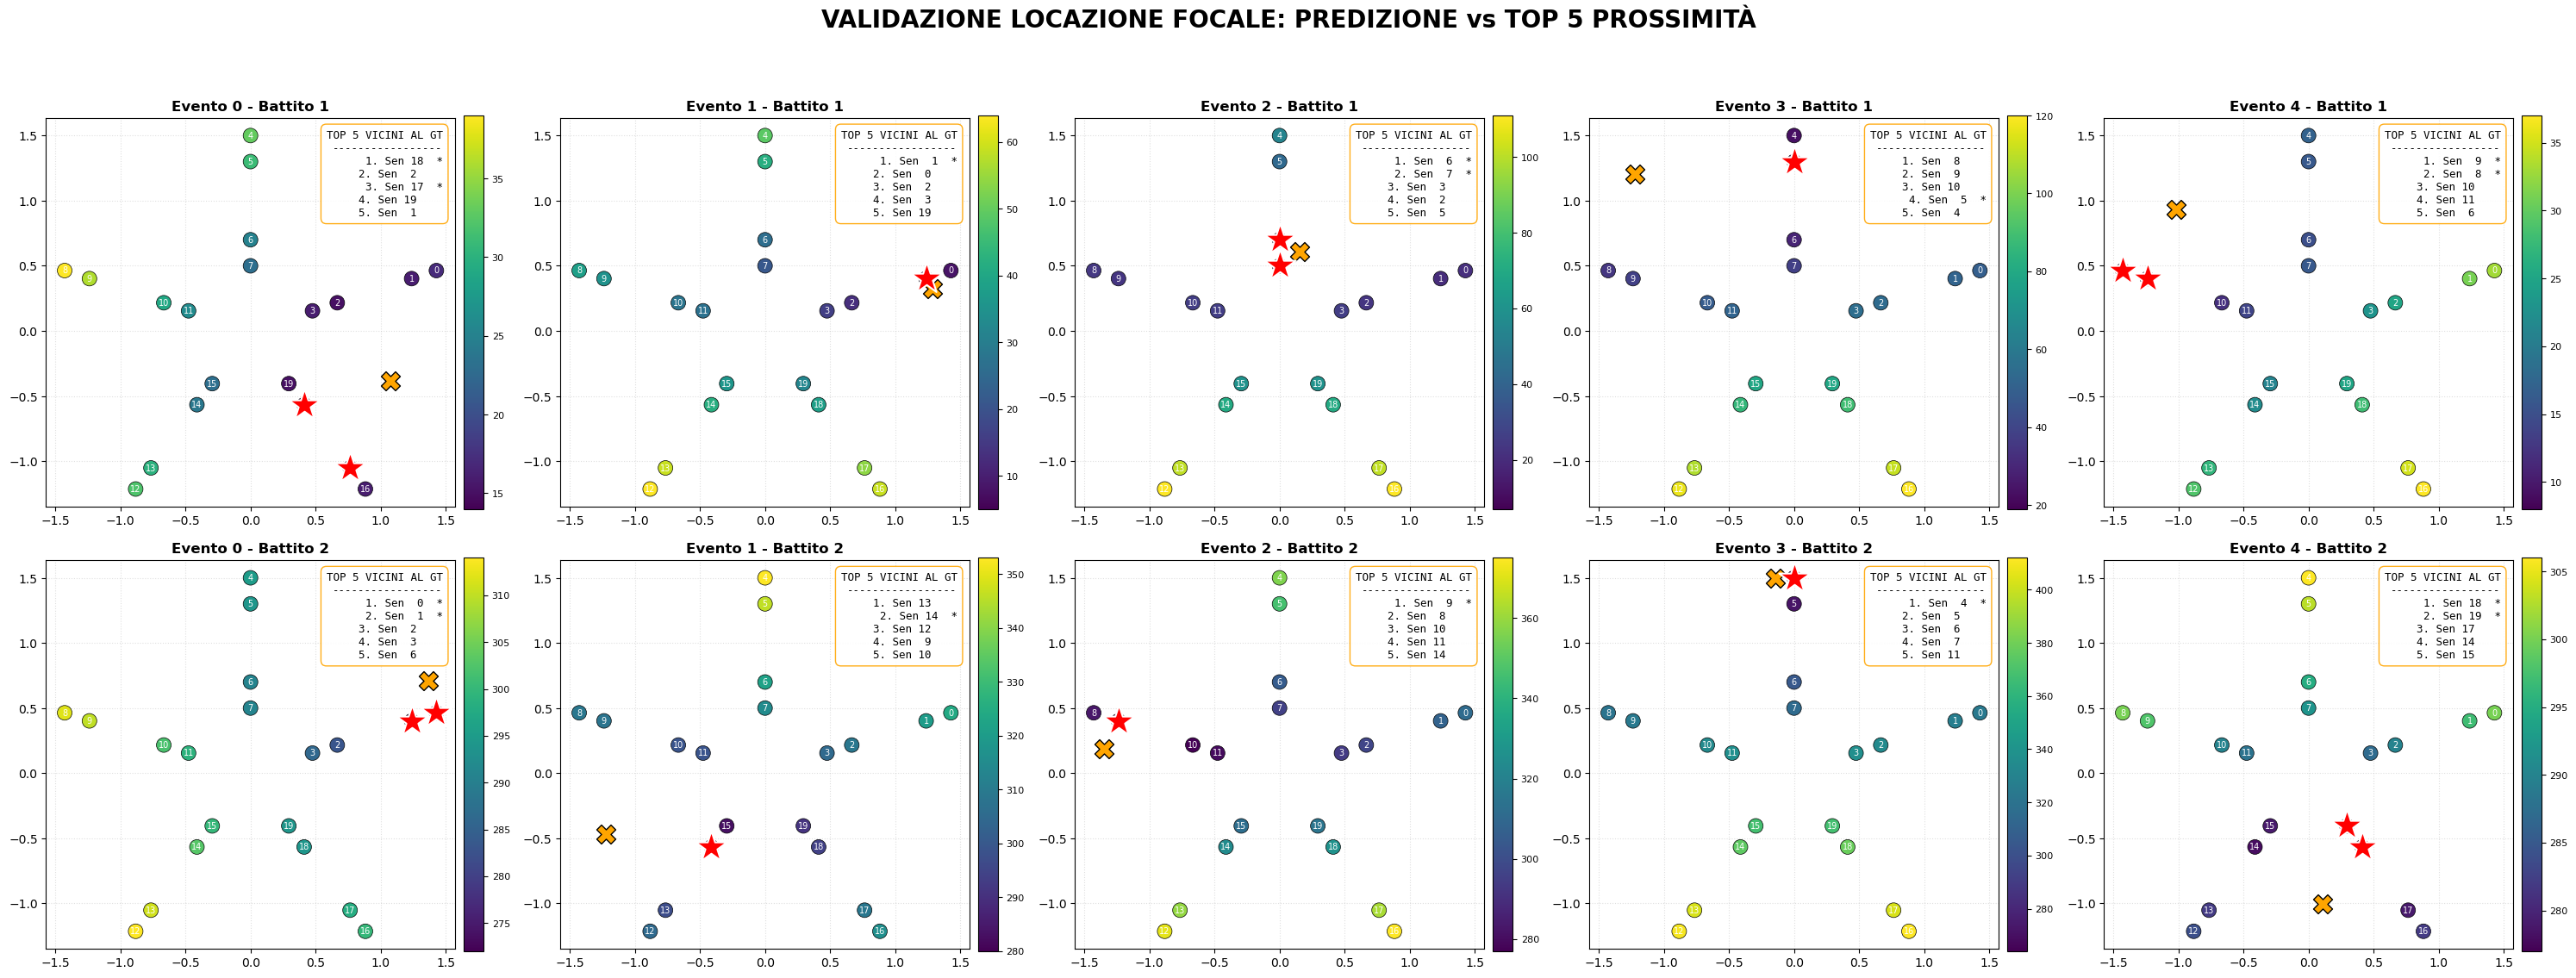

In [7]:
sensor_locs_raw = np.load('checkpoint1sensorlocations.npy')
gt_focal = np.load('checkpoint1FocalPoints.npy')

# --- CONFIGURAZIONE DATI ---
sensor_locs = sensor_locs_raw - 2
n_events = gt_focal.shape[0]

# Creazione figura: una colonna per evento, due righe (Beat 1 e Beat 2)
fig, axes = plt.subplots(2, n_events, figsize=(6 * n_events, 12), squeeze=False)

for ev in range(n_events):
    sig_ev = signals[ev, :, :]
    
    # Esecuzione della funzione di calcolo
    timings, LS = GroupSolutionCP1(sig_ev)
    
    timings_arr = np.array(timings, dtype=float)
    ls_arr = np.array(LS, dtype=float)

    for beat_idx in range(2):
        ax = axes[beat_idx, ev]
        gp = gt_focal[ev, beat_idx] # Punto reale (Arancione)

        # 1. Calcolo distanze dal Ground Truth per trovare i 5 più vicini
        distanze = np.sqrt(np.sum((sensor_locs - gp)**2, axis=1))
        top5_idxs = np.argsort(distanze)[:5]
        
        # 2. Identificazione sensori scelti dall'algoritmo (Predizione)
        pred_idxs = np.where(ls_arr[:, beat_idx] > 0)[0]

        # 3. Plot dei sensori (sfumatura di colore per il tempo di attivazione)
        valori_colore = timings_arr[:, beat_idx]
        mask_valid = np.isfinite(valori_colore)
        
        if np.any(mask_valid):
            sc = ax.scatter(
                sensor_locs[mask_valid, 0], sensor_locs[mask_valid, 1],
                c=valori_colore[mask_valid], cmap='viridis', 
                s=150, edgecolors='k', linewidths=0.5, zorder=2
            )
            cbar = plt.colorbar(sc, ax=ax, fraction=0.045, pad=0.02)
            cbar.ax.tick_params(labelsize=8)
        else:
            ax.scatter(sensor_locs[:, 0], sensor_locs[:, 1], c='lightgrey', s=80, alpha=0.3)

        # 4. Plot icone: Croce Arancione (GT) e Stella Rossa (PRED)
        ax.scatter(gp[0], gp[1], marker='X', s=250, c='orange', 
                   edgecolors='black', linewidths=1, zorder=5, label='GT')

        if len(pred_idxs) > 0:
            ax.scatter(
                sensor_locs[pred_idxs, 0], sensor_locs[pred_idxs, 1],
                marker='*', s=750, c='red', edgecolors='white', 
                linewidths=1.5, zorder=10, label='PRED'
            )

        # 5. CREAZIONE BOX INFO (La parte che volevi "carina")
        # Usiamo un font monospace per allineare i numeri come una tabella
        info_lines = ["TOP 5 VICINI AL GT", "-----------------"]
        for rank, s_idx in enumerate(top5_idxs, 1):
            # Aggiunge la spunta se il sensore vicino è stato anche predetto
            status = " *" if s_idx in pred_idxs else "   "
            info_lines.append(f"{rank}. Sen {s_idx:2d} {status}")
        
        # Se la predizione è fuori dalla Top 5, lo segnaliamo in rosso (concettualmente)
        for p in pred_idxs:
            if p not in top5_idxs:
                info_lines.append(f"!. Sen {p:2d} X (Out)")

        info_text = "\n".join(info_lines)
        
        ax.text(0.97, 0.97, info_text, transform=ax.transAxes, fontsize=9,
                verticalalignment='top', horizontalalignment='right', family='monospace',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='orange'))

        # Numeri identificativi sui sensori
        for i, (x, y) in enumerate(sensor_locs):
            ax.text(x, y, str(i), fontsize=7, ha='center', va='center', color='white', zorder=3)

        # Estetica grafico
        ax.set_aspect('equal')
        ax.grid(True, linestyle=':', alpha=0.4)
        ax.set_title(f'Evento {ev} - Battito {beat_idx+1}', fontsize=12, fontweight='bold')

plt.suptitle('VALIDAZIONE LOCAZIONE FOCALE: PREDIZIONE vs TOP 5 PROSSIMITÀ', 
             fontsize=20, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [8]:
# # loop su tutti gli eventi
# for ind_event in range(5):

#     # loop su tutte le spline
#     for ind_spline in range(5):

#         #plt.figure()

#         countEL = 1
#         for indS in np.arange(ind_spline*4, (ind_spline+1)*4, 1):

#             plt.subplot(4,1,countEL)
#             plt.plot(signals[ind_event, indS, :])
#             plt.grid(True)

#             countEL += 1

#         #plt.suptitle(f"Event {ind_event} - Spline {ind_spline}")
#         #plt.show()

#     # test della soluzione per l'evento
#     signals_event = signals[ind_event, :, :]
#     timings_event, LS_event = GroupSolutionCP1(signals_event)

#     print("Event:", ind_event)
#     print("timings_event:", timings_event)
#     print("LS_event:", LS_event)
#     print("--------------------")